# Notebook 05: Shrinking the tree (Stage 6)

**Research question:** how much detection performance can be retained while reducing
the computational, memory and model-size requirements of a machine-learning-based
threat detector?

Notebook 4 trained one full-size (untuned) decision tree per feature list. This
notebook makes the trees **smaller on purpose** and measures what is lost, class by
class. It has six parts:

| Part | What it does | Output files in `experiments/` |
|---|---|---|
| 1 | Re-runs the Stage 5 baseline (notebook 4, Steps 4-9) with the new 58-feature list A, so every number comes from the same run and library versions | `results.csv` (S5 rows), `S5_*.csv` |
| 2 | Simple baseline: a "model" that calls every flow BENIGN | `S6_majority_baseline.csv` |
| 3 | **Depth sweep**: max_depth 1 to 20 and unlimited, on 8 feature lists (A-D, and A-D without the shortcut features), on 5 different random train/test splits | `S6_depth_sweep.csv` |
| 4 | **Pruning sweep**: cost-complexity pruning (ccp_alpha), split 42 only | `S6_ccp_sweep.csv` |
| 5 | **Choosing the smallest good tree on a validation set** (never on the test set) | `S6_validation_choice.csv`, `results.csv` (S6 rows) |
| 6 | Summary tables and figures for the paper | `S6_summary_*.csv`, `figures/` |

**What every number means** is explained in `experiments/README.md`.

**Runtime:** about 1.5 hours on a 2-core CPU (Colab's free CPU runtime is similar).
Set `QUICK = True` in the setup cell for a 2-minute test run that only checks the code
works (its numbers are NOT the paper's numbers and nothing is written to `experiments/`).

**Input:** the raw `Wednesday-workingHours.pcap_ISCX.csv`. The cleaning and the split
are repeated here exactly as in notebook 2, because Part 3 needs the cleaned table to
make the 4 extra splits. Split 42 is checked against notebook 2's `y_train.csv` /
`y_test.csv` when those files are available.

In [1]:
# Setup
import os
import gc
import json
import time
import datetime
import tempfile
import tracemalloc
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import sklearn
import matplotlib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support

QUICK = os.environ.get("QUICK", "0") == "1"   # True = fast code check only

# ---- Paths: works locally (repo layout) and in Colab (Drive layout from notebooks 3-4) ----
try:
    from google.colab import drive  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/threat detector")
    REPO_DIR = PROJECT_DIR                    # results are written next to the Drive data
else:
    REPO_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    PROJECT_DIR = REPO_DIR

DATA_DIR = PROJECT_DIR / "data"
RAW_CSV = DATA_DIR / "Wednesday-workingHours.pcap_ISCX.csv"
FEATURE_SETS_JSON = REPO_DIR / "experiments" / "feature_sets.json"
if not FEATURE_SETS_JSON.exists():                 # Colab: notebook 3 saved it in data/
    FEATURE_SETS_JSON = DATA_DIR / "feature_sets.json"

OUT_DIR = REPO_DIR / ("experiments_quick_test" if QUICK else "experiments")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- Experiment settings ----
SEEDS = [42] if QUICK else [42, 43, 44, 45, 46]   # 42 = the split used in notebooks 2-4
DEPTHS = [2, None] if QUICK else [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None]   # None = unlimited
CCP_ALPHAS = [0.0, 1e-4] if QUICK else [0.0, 1e-7, 3e-7, 1e-6, 3e-6, 1e-5, 3e-5,
                                        1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2]
N_PREDICT_REPEATS = 5        # median of 5 timings, as in notebook 4
BATCH_ROWS = 1000            # memory is measured for classifying 1,000 flows, as in notebook 4
BENIGN = "BENIGN"
HEARTBLEED = "Heartbleed"

print("Running in", "Colab" if IN_COLAB else "local mode", "| QUICK =", QUICK)
print("Raw CSV:", RAW_CSV)
print("Writing results to:", OUT_DIR)
print("Library versions: scikit-learn", sklearn.__version__, "| pandas", pd.__version__,
      "| numpy", np.__version__)

Running in local mode | QUICK = False
Raw CSV: /home/user/threat-detection-model/data/Wednesday-workingHours.pcap_ISCX.csv
Writing results to: /home/user/threat-detection-model/experiments
Library versions: scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3


## Load and clean the data (same steps as notebook 2)

In [2]:
df = pd.read_csv(RAW_CSV)
df.columns = df.columns.str.strip()
assert df.shape == (692703, 79), df.shape

numeric_cols = df.select_dtypes(include=np.number).columns
inf_mask = np.isinf(df[numeric_cols]).any(axis=1)
df = df[~inf_mask].copy()
df = df.dropna().copy()
df = df.drop_duplicates().copy()
assert len(df) == 610492, len(df)   # notebook 2: 692,703 - 1,297 - 80,914

X_all = df.drop(columns=["Label"])
y_all = df["Label"]
CLASS_LABELS = sorted(y_all.unique())
MAIN_CLASSES = [c for c in CLASS_LABELS if c != HEARTBLEED]
print("Cleaned:", df.shape)
print(y_all.value_counts().to_string())


def make_split(seed):
    """80/20 stratified split, exactly like notebook 2 (which used seed 42)."""
    return train_test_split(X_all, y_all, test_size=0.2, random_state=seed, stratify=y_all)


# Check: split 42 is the same split notebooks 2-4 used
X_train, X_test, y_train, y_test = make_split(42)
assert X_train.shape == (488393, 78) and X_test.shape == (122099, 78)
for name, ours in [("y_train.csv", y_train), ("y_test.csv", y_test)]:
    path = DATA_DIR / name
    if path.exists():
        theirs = pd.read_csv(path).squeeze("columns")
        assert (ours.to_numpy() == theirs.to_numpy()).all(), f"{name} differs from notebook 2"
        print(f"{name}: identical to notebook 2, row for row")
    else:
        print(f"{name} not found, so the row-for-row check was skipped")

Cleaned: (610492, 79)
Label
BENIGN              416736
DoS Hulk            172846
DoS GoldenEye        10286
DoS slowloris         5385
DoS Slowhttptest      5228
Heartbleed              11


y_train.csv: identical to notebook 2, row for row
y_test.csv: identical to notebook 2, row for row


## Feature lists

A, B, C, D come from notebook 3. The **shortcut-free** versions (`A-NS` ... `D-NS`)
remove the three features that may describe the lab rather than the attack
(notebook 4, Step 6): `Destination Port`, `Init_Win_bytes_forward` and
`Init_Win_bytes_backward`.

In [3]:
with open(FEATURE_SETS_JSON) as f:
    base_sets = json.load(f)

SHORTCUT_FEATURES = ["Destination Port", "Init_Win_bytes_forward", "Init_Win_bytes_backward"]
FEATURE_SETS = {}
for name in ["A", "B", "C", "D"]:
    FEATURE_SETS[name] = list(base_sets[name])
for name in ["A", "B", "C", "D"]:
    FEATURE_SETS[f"{name}-NS"] = [c for c in base_sets[name] if c not in SHORTCUT_FEATURES]

EXPECTED = {"A": 58, "B": 39, "C": 15, "D": 6, "A-NS": 55, "B-NS": 36, "C-NS": 13, "D-NS": 4}
for name, n in EXPECTED.items():
    assert len(FEATURE_SETS[name]) == n, (name, len(FEATURE_SETS[name]))
    assert all(c in X_all.columns for c in FEATURE_SETS[name])
print({k: len(v) for k, v in FEATURE_SETS.items()})
if QUICK:
    FEATURE_SETS = {k: FEATURE_SETS[k] for k in ["A", "D-NS"]}

{'A': 58, 'B': 39, 'C': 15, 'D': 6, 'A-NS': 55, 'B-NS': 36, 'C-NS': 13, 'D-NS': 4}


## Measuring one tree

`evaluate()` scores a trained tree on the test set and measures its cost. Besides the
numbers notebook 4 already recorded, it adds two that do not depend on the computer:

- **Average comparisons per flow**: how many yes/no questions the tree asks, on
  average, before it reaches an answer. This is the tree's real amount of work.
- **Compact size**: the bytes needed to store the tree as plain arrays, the way it
  would be stored on a small device: for every node, a feature number (1 byte), a
  threshold (4-byte float) and two child numbers (2 bytes each if the tree has fewer
  than 65,536 nodes, otherwise 4 bytes). The saved `.joblib` file is much bigger
  because it also stores Python bookkeeping. To prove the compact version is not a
  guess, `compact_predict()` classifies the test set using only those arrays, and the
  result is checked against scikit-learn's own predictions.

In [4]:
def compact_arrays(model):
    t = model.tree_
    thr = t.threshold.astype(np.float32)
    # scikit-learn compares float32 inputs with float64 thresholds. Rounding a threshold
    # DOWN to the nearest float32 keeps every comparison exactly the same.
    went_up = thr.astype(np.float64) > t.threshold
    thr[went_up] = np.nextafter(thr[went_up], np.float32(-np.inf))
    n = t.node_count
    index_bytes = 2 if n <= 65535 else 4
    return {
        "feature": t.feature, "threshold": thr,
        "left": t.children_left, "right": t.children_right,
        "leaf_class": t.value[:, 0, :].argmax(axis=1),
        "bytes": n * (1 + 4 + 2 * index_bytes),
    }


def compact_predict(arrays, X, classes):
    Xv = X.to_numpy(dtype=np.float32)
    node = np.zeros(len(Xv), dtype=np.int64)
    rows = np.arange(len(Xv))
    while True:
        active = arrays["left"][node] != -1
        if not active.any():
            break
        r, nd = rows[active], node[active]
        go_left = Xv[r, arrays["feature"][nd]] <= arrays["threshold"][nd]
        node[r] = np.where(go_left, arrays["left"][nd], arrays["right"][nd])
    return classes[arrays["leaf_class"][node]]


def evaluate(model, cols, Xte, yte, measure_cost=True):
    Xte = Xte[cols]
    # ---- prediction time (median of 5) ----
    times = []
    for _ in range(N_PREDICT_REPEATS if measure_cost else 1):
        t0 = time.perf_counter()
        y_pred = model.predict(Xte)
        times.append(time.perf_counter() - t0)
    y_true = yte.to_numpy()

    # ---- detection ----
    real_attack = y_true != BENIGN
    said_attack = y_pred != BENIGN
    missed = int((real_attack & ~said_attack).sum())
    false_alarms = int((~real_attack & said_attack).sum())
    _, rec, _, sup = precision_recall_fscore_support(
        y_true, y_pred, labels=CLASS_LABELS, zero_division=0)
    out = {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1_all": f1_score(y_true, y_pred, labels=CLASS_LABELS, average="macro", zero_division=0),
        "macro_f1_no_hb": f1_score(y_true, y_pred, labels=MAIN_CLASSES, average="macro", zero_division=0),
        "attack_recall": 1 - missed / real_attack.sum(),
        "missed": missed,
        "false_alarms": false_alarms,
        "false_alarm_rate": false_alarms / (~real_attack).sum(),
        "attack_test_rows": int(real_attack.sum()),
        "benign_test_rows": int((~real_attack).sum()),
    }
    for c, r, s in zip(CLASS_LABELS, rec, sup):
        key = c.replace(" ", "_")
        out[f"recall_{key}"] = r
        out[f"caught_{key}"] = int(round(r * s))
        out[f"rows_{key}"] = int(s)

    # ---- size and work ----
    t = model.tree_
    out["depth_reached"] = int(model.get_depth())
    out["nodes"] = int(t.node_count)
    out["leaves"] = int(model.get_n_leaves())
    out["avg_comparisons"] = float(model.decision_path(Xte).sum(axis=1).mean() - 1)
    arrays = compact_arrays(model)
    out["compact_bytes"] = arrays["bytes"]
    imp = pd.Series(model.feature_importances_, index=cols).sort_values(ascending=False)
    out["root_feature"] = cols[t.feature[0]] if t.node_count > 1 else ""
    out["top3_features"] = "; ".join(imp.index[:3][imp.values[:3] > 0])
    out["uses_shortcut_feature"] = bool(any(imp.get(c, 0) > 0 for c in SHORTCUT_FEATURES))

    if measure_cost:
        out["inference_ms_per_1000"] = float(np.median(times)) * 1000 / len(Xte) * 1000
        out["compact_matches_sklearn"] = bool(
            (compact_predict(arrays, Xte, model.classes_) == y_pred).all())
        # saved file size (same as notebook 4)
        with tempfile.TemporaryDirectory() as tmp:
            p = Path(tmp) / "m.joblib"
            joblib.dump(model, p)
            out["joblib_kb"] = os.path.getsize(p) / 1024
        # memory (same method as notebook 4, Step 9b)
        state = t.__getstate__()
        tree_mb = (state["nodes"].nbytes + state["values"].nbytes) / 1024**2
        batch = Xte.iloc[:BATCH_ROWS]
        gc.collect()
        tracemalloc.start()
        model.predict(batch)
        _, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        out["tree_in_memory_mb"] = tree_mb
        out["predict_1000_rows_peak_mb"] = peak / 1024**2
        out["ram_mb"] = tree_mb + peak / 1024**2
    return out, y_pred


def train_and_evaluate(Xtr, ytr, Xte, yte, cols, seed, measure_cost=True, **tree_kwargs):
    model = DecisionTreeClassifier(random_state=seed, **tree_kwargs)
    t0 = time.perf_counter()
    model.fit(Xtr[cols], ytr)
    train_s = time.perf_counter() - t0
    out, y_pred = evaluate(model, cols, Xte, yte, measure_cost)
    out["training_time_s"] = train_s
    return out, y_pred, model

## Part 1: re-run the Stage 5 baseline (notebook 4, Steps 4-9)

Same 8 runs as notebook 4 (untuned tree, `random_state=42`, split 42), but with the
new 58-feature list A. Shortcut runs keep notebook 4's definitions:
`A_no_port` (57), `A_no_port_no_window` (55), `C_no_port` (14), `D_no_port` (5).

In [5]:
PORT = "Destination Port"
WINDOW = ["Init_Win_bytes_forward", "Init_Win_bytes_backward"]
S5_RUNS = {
    "A": base_sets["A"], "B": base_sets["B"], "C": base_sets["C"], "D": base_sets["D"],
    "A_no_port": [c for c in base_sets["A"] if c != PORT],
    "A_no_port_no_window": [c for c in base_sets["A"] if c not in [PORT] + WINDOW],
    "C_no_port": [c for c in base_sets["C"] if c != PORT],
    "D_no_port": [c for c in base_sets["D"] if c != PORT],
}
if QUICK:
    S5_RUNS = {k: S5_RUNS[k] for k in ["D", "D_no_port"]}

today = datetime.date.today().isoformat()
s5 = {}
s5_pred = {}
for name, cols in S5_RUNS.items():
    out, y_pred, _ = train_and_evaluate(X_train, y_train, X_test, y_test, cols, seed=42)
    s5[name] = {"run": name, "num_features": len(cols), **out}
    s5_pred[name] = y_pred
    print(f"[{name}] {len(cols)} features | attack recall {out['attack_recall']:.6f} "
          f"(missed {out['missed']}, false alarms {out['false_alarms']}) | "
          f"macro F1 no HB {out['macro_f1_no_hb']:.4f} | {out['nodes']} nodes | "
          f"{out['joblib_kb']:.1f} KB | {out['ram_mb']:.3f} MB")
s5_df = pd.DataFrame(s5.values())

[A] 58 features | attack recall 0.999071 (missed 36, false alarms 21) | macro F1 no HB 0.9967 | 823 nodes | 92.8 KB | 0.758 MB


[B] 39 features | attack recall 0.998890 (missed 43, false alarms 28) | macro F1 no HB 0.9955 | 891 nodes | 99.9 KB | 0.548 MB


[C] 15 features | attack recall 0.999019 (missed 38, false alarms 34) | macro F1 no HB 0.9958 | 997 nodes | 111.1 KB | 0.285 MB


[D] 6 features | attack recall 0.998245 (missed 68, false alarms 66) | macro F1 no HB 0.9924 | 1487 nodes | 164.5 KB | 0.248 MB


[A_no_port] 57 features | attack recall 0.998529 (missed 57, false alarms 46) | macro F1 no HB 0.9922 | 1143 nodes | 127.8 KB | 0.781 MB


[A_no_port_no_window] 55 features | attack recall 0.993807 (missed 240, false alarms 112) | macro F1 no HB 0.9912 | 2859 nodes | 315.4 KB | 0.941 MB


[C_no_port] 14 features | attack recall 0.998426 (missed 61, false alarms 70) | macro F1 no HB 0.9926 | 1603 nodes | 177.3 KB | 0.338 MB


[D_no_port] 5 features | attack recall 0.996490 (missed 136, false alarms 149) | macro F1 no HB 0.9864 | 2839 nodes | 312.3 KB | 0.388 MB


In [6]:
# Save Part 1 in the same layouts notebook 4 used
RESULTS_COLUMNS = ["experiment_id", "date", "stage", "dataset_file", "num_samples", "num_features",
                   "features_used", "max_depth", "num_nodes", "accuracy", "precision", "recall", "f1",
                   "model_size_kb", "training_time_s", "inference_ms", "ram_mb", "notes"]
rows = []
for name in S5_RUNS:
    r = s5[name]
    p, rc, f, _ = precision_recall_fscore_support(y_test, s5_pred[name], average="macro", zero_division=0)
    rows.append({
        "experiment_id": f"S5-{name}", "date": today, "stage": "5-baseline",
        "dataset_file": "Wednesday-workingHours", "num_samples": len(X_train) + len(X_test),
        "num_features": r["num_features"], "features_used": name,
        "max_depth": r["depth_reached"], "num_nodes": r["nodes"],
        "accuracy": round(r["accuracy"], 6), "precision": round(p, 6), "recall": round(rc, 6),
        "f1": round(f, 6), "model_size_kb": round(r["joblib_kb"], 2),
        "training_time_s": round(r["training_time_s"], 3),
        "inference_ms": round(r["inference_ms_per_1000"], 4), "ram_mb": round(r["ram_mb"], 4),
        "notes": (f"re-run in notebook 05 (scikit-learn {sklearn.__version__}); untuned "
                  f"DecisionTreeClassifier(random_state=42); precision/recall/f1 are macro; "
                  f"inference_ms = ms per 1000 test rows (median of {N_PREDICT_REPEATS} predict runs); "
                  f"attack recall={r['attack_recall']:.6f}; missed attacks={r['missed']}; "
                  f"false alarms={r['false_alarms']}; ram_mb = tree in memory + peak extra memory "
                  f"to classify 1000 rows (excludes Python/scikit-learn itself)"),
    })
s5_results = pd.DataFrame(rows, columns=RESULTS_COLUMNS)

recall_tbl = pd.DataFrame({n: {c: s5[n][f"recall_{c.replace(' ', '_')}"] for c in CLASS_LABELS}
                           for n in S5_RUNS})
recall_tbl.insert(0, "test rows", [s5[next(iter(S5_RUNS))][f"rows_{c.replace(' ', '_')}"]
                                   for c in CLASS_LABELS])
recall_tbl.index.name = "class"
no_hb_tbl = s5_df[["run", "num_features", "macro_f1_all", "macro_f1_no_hb", "attack_recall"]].copy()
no_hb_tbl.columns = ["run", "num_features", "macro_f1_all_classes", "macro_f1_without_heartbleed",
                     "attack_recall"]
no_hb_tbl.insert(4, "weighted_f1", [f1_score(y_test, s5_pred[n], average="weighted", zero_division=0)
                                    for n in S5_RUNS])
no_hb_tbl["heartbleed_caught_of_2"] = s5_df["caught_Heartbleed"].values
mem_tbl = s5_df[["run", "tree_in_memory_mb", "predict_1000_rows_peak_mb", "ram_mb"]].rename(
    columns={"ram_mb": "total_mb"})

if not QUICK:
    s5_results.to_csv(OUT_DIR / "results.csv", index=False)   # S6 rows are appended in Part 5
    recall_tbl.to_csv(OUT_DIR / "S5_per_class_recall.csv")
    no_hb_tbl.to_csv(OUT_DIR / "S5_scores_without_heartbleed.csv", index=False)
    mem_tbl.to_csv(OUT_DIR / "S5_memory.csv", index=False)
display(s5_results.drop(columns=["notes"]))

,experiment_id,date,stage,dataset_file,num_samples,num_features,features_used,max_depth,num_nodes,accuracy,precision,recall,f1,model_size_kb,training_time_s,inference_ms,ram_mb
0,S5-A,2026-10-29,5-baseline,Wednesday-workingHours,610492,58,A,31,823,0.999435,0.997710,0.913514,0.941723,92.77,26.031,0.3854,0.7584
1,S5-B,2026-10-29,5-baseline,Wednesday-workingHours,610492,39,B,31,891,0.999296,0.996348,0.912765,0.940667,99.92,20.853,0.2476,0.5479
2,S5-C,2026-10-29,5-baseline,Wednesday-workingHours,610492,15,C,31,997,0.999296,0.829447,0.830300,0.829870,111.06,6.516,0.1267,0.2847
3,S5-D,2026-10-29,5-baseline,Wednesday-workingHours,610492,6,D,32,1487,0.998780,0.909839,0.910906,0.910370,164.48,2.405,0.0802,0.2478
4,S5-A_no_port,2026-10-29,5-baseline,Wednesday-workingHours,610492,57,A_no_port,30,1143,0.999009,0.993897,0.909720,0.937918,127.76,24.865,0.2581,0.7810
5,S5-A_no_port_no_window,2026-10-29,5-baseline,Wednesday-workingHours,610492,55,A_no_port_no_window,51,2859,0.996978,0.993355,0.908621,0.937096,315.38,24.258,0.2990,0.9414
6,S5-C_no_port,2026-10-29,5-baseline,Wednesday-workingHours,610492,14,C_no_port,31,1603,0.998829,0.826415,0.827887,0.827149,177.32,6.167,0.1105,0.3380
7,S5-D_no_port,2026-10-29,5-baseline,Wednesday-workingHours,610492,5,D_no_port,33,2839,0.997584,0.987664,0.906304,0.933092,312.34,2.638,0.0961,0.3883


## Part 2: simplest possible baseline

A "detector" that calls every flow BENIGN. Any real model must beat this. Its
accuracy shows why accuracy alone is misleading here: about 68% of test flows are
benign, so it scores about 0.68 while catching zero attacks.

In [7]:
maj_rows = []
for seed in SEEDS:
    _, _, ytr_s, yte_s = make_split(seed)
    y_pred = np.full(len(yte_s), BENIGN, dtype=object)
    real_attack = (yte_s != BENIGN).to_numpy()
    maj_rows.append({
        "seed": seed,
        "accuracy": accuracy_score(yte_s, y_pred),
        "macro_f1_no_hb": f1_score(yte_s, y_pred, labels=MAIN_CLASSES, average="macro", zero_division=0),
        "attack_recall": 0.0, "missed": int(real_attack.sum()), "false_alarms": 0,
    })
maj_df = pd.DataFrame(maj_rows)
if not QUICK:
    maj_df.to_csv(OUT_DIR / "S6_majority_baseline.csv", index=False)
display(maj_df)

,seed,accuracy,macro_f1_no_hb,attack_recall,missed,false_alarms
0,42,0.682626,0.162276,0.0,38751,0
1,43,0.682626,0.162276,0.0,38751,0
2,44,0.682626,0.162276,0.0,38751,0
3,45,0.682626,0.162276,0.0,38751,0
4,46,0.682626,0.162276,0.0,38751,0


## Part 3: depth sweep (the main experiment)

For each of 5 train/test splits, each of 8 feature lists and each depth limit, train a
tree and measure everything. Split 42 is the notebook 2 split; 43-46 are new random
splits made the same way, to see how much the results move by chance.
The tree's own `random_state` is set to the same number as the split.

Rows are saved after every split, so an interrupted run loses at most one split.

In [8]:
def depth_label(d):
    return "none" if d is None else str(d)


sweep_path = OUT_DIR / "S6_depth_sweep.csv"
sweep_rows = []
t_start = time.perf_counter()
for seed in SEEDS:
    Xtr, Xte, ytr, yte = make_split(seed)
    for set_name, cols in FEATURE_SETS.items():
        for d in DEPTHS:
            out, _, _ = train_and_evaluate(Xtr, ytr, Xte, yte, cols, seed=seed, max_depth=d)
            sweep_rows.append({"seed": seed, "feature_set": set_name,
                               "shortcut_free": set_name.endswith("-NS"),
                               "num_features": len(cols), "max_depth": depth_label(d), **out})
        last = sweep_rows[-1]
        print(f"split {seed} | {set_name:5s} done | full tree: {last['nodes']} nodes, "
              f"attack recall {last['attack_recall']:.4f} | {time.perf_counter() - t_start:.0f} s so far")
    if not QUICK:
        pd.DataFrame(sweep_rows).to_csv(sweep_path, index=False)
sweep = pd.DataFrame(sweep_rows)
print("Every compact tree gave exactly the same predictions as scikit-learn:",
      bool(sweep["compact_matches_sklearn"].all()))
assert sweep["compact_matches_sklearn"].all()

split 42 | A     done | full tree: 823 nodes, attack recall 0.9991 | 161 s so far


split 42 | B     done | full tree: 891 nodes, attack recall 0.9989 | 285 s so far


split 42 | C     done | full tree: 997 nodes, attack recall 0.9990 | 349 s so far


split 42 | D     done | full tree: 1487 nodes, attack recall 0.9982 | 388 s so far


split 42 | A-NS  done | full tree: 2859 nodes, attack recall 0.9938 | 534 s so far


...

split 46 | D     done | full tree: 1491 nodes, attack recall 0.9985 | 3449 s so far


split 46 | A-NS  done | full tree: 2825 nodes, attack recall 0.9942 | 3602 s so far


split 46 | B-NS  done | full tree: 3371 nodes, attack recall 0.9933 | 3725 s so far


split 46 | C-NS  done | full tree: 3991 nodes, attack recall 0.9927 | 3791 s so far


split 46 | D-NS  done | full tree: 16279 nodes, attack recall 0.9706 | 3835 s so far
Every compact tree gave exactly the same predictions as scikit-learn: True


## Part 4: pruning sweep (cost-complexity pruning, split 42 only)

Depth limits cut every branch at the same level. Cost-complexity pruning
(`ccp_alpha`, Breiman et al., 1984) instead removes the branches that add the least,
wherever they are. A bigger `ccp_alpha` means more pruning. This checks that the
depth-sweep conclusions are not just a side effect of how the tree was shrunk.

In [9]:
ccp_rows = []
for set_name, cols in FEATURE_SETS.items():
    for a in CCP_ALPHAS:
        out, _, _ = train_and_evaluate(X_train, y_train, X_test, y_test, cols, seed=42, ccp_alpha=a)
        ccp_rows.append({"seed": 42, "feature_set": set_name, "shortcut_free": set_name.endswith("-NS"),
                         "num_features": len(cols), "ccp_alpha": a, **out})
    print(f"{set_name} done")
ccp = pd.DataFrame(ccp_rows)
assert ccp["compact_matches_sklearn"].all()
if not QUICK:
    ccp.to_csv(OUT_DIR / "S6_ccp_sweep.csv", index=False)
display(ccp[["feature_set", "ccp_alpha", "nodes", "depth_reached", "attack_recall",
             "macro_f1_no_hb", "compact_bytes"]].round(5))

A done


B done


C done


D done


A-NS done


B-NS done


C-NS done


D-NS done


,feature_set,ccp_alpha,nodes,depth_reached,attack_recall,macro_f1_no_hb,compact_bytes
0,A,0.0000,823,31,0.99907,0.99673,7407
1,A,0.0000,821,31,0.99907,0.99673,7389
2,A,0.0000,821,31,0.99907,0.99673,7389
3,A,0.0000,743,28,0.99925,0.99676,6687
4,A,0.0000,365,22,0.99959,0.99658,3285
...,...,...,...,...,...,...,...
99,D-NS,0.0003,127,12,0.96398,0.93406,1143
100,D-NS,0.0010,57,10,0.93770,0.84378,513
101,D-NS,0.0030,47,10,0.94227,0.80653,423
102,D-NS,0.0100,5,2,0.71941,0.36359,45


## Part 5: choosing the smallest good tree, on a validation set

Picking the "best small tree" by looking at the test set would be cheating (Arp et
al. 2022, pitfall "biased parameter selection"). So the choice is made on a
**validation set**: 20% of the training set (split 42), stratified. Trees are
trained on the other 80% of the training set.

**Rule (fixed before looking at any test result):** the chosen depth is the smallest
depth limit at which **every class except Heartbleed** keeps its validation recall
within **1 percentage point** of the unlimited tree's. Heartbleed is left out because
the validation set has only 2 Heartbleed flows. A stricter version (0.1 points) is
also reported to show how much the answer depends on the threshold.

The chosen depth is then looked up in the Part 3 results (trained on the whole
training set, scored on the test set, 5 splits).

In [10]:
X_in, X_val, y_in, y_val = train_test_split(X_train, y_train, test_size=0.2,
                                            random_state=42, stratify=y_train)
val_rows = []
for set_name, cols in FEATURE_SETS.items():
    for d in DEPTHS:
        out, _, _ = train_and_evaluate(X_in, y_in, X_val, y_val, cols, seed=42,
                                       measure_cost=False, max_depth=d)
        val_rows.append({"feature_set": set_name, "max_depth": depth_label(d), **out})
val = pd.DataFrame(val_rows)

MAIN_KEYS = [f"recall_{c.replace(' ', '_')}" for c in MAIN_CLASSES]
choice_rows = []
for set_name in FEATURE_SETS:
    v = val[val["feature_set"] == set_name].reset_index(drop=True)
    full = v[v["max_depth"] == "none"].iloc[0]
    row = {"feature_set": set_name, "num_features": len(FEATURE_SETS[set_name]),
           "val_rows_heartbleed": int(full["rows_Heartbleed"])}
    for tol_name, tol in [("1pt", 0.01), ("0.1pt", 0.001)]:
        ok = v[(v[MAIN_KEYS] >= full[MAIN_KEYS].to_numpy() - tol).all(axis=1)]
        row[f"chosen_depth_{tol_name}"] = ok.iloc[0]["max_depth"]   # DEPTHS go small -> large
        row[f"worst_class_gap_{tol_name}"] = float((full[MAIN_KEYS].to_numpy()
                                                    - ok.iloc[0][MAIN_KEYS].to_numpy()).max())
    choice_rows.append(row)
choice = pd.DataFrame(choice_rows)
if not QUICK:
    val.to_csv(OUT_DIR / "S6_validation_sweep.csv", index=False)
    choice.to_csv(OUT_DIR / "S6_validation_choice.csv", index=False)
display(choice)

,feature_set,num_features,val_rows_heartbleed,chosen_depth_1pt,worst_class_gap_1pt,chosen_depth_0.1pt,worst_class_gap_0.1pt
0,A,58,2,20,0.002392,none,0.000000
1,B,39,2,20,0.005981,none,0.000000
2,C,15,2,12,0.006683,15,0.000000
3,D,6,2,12,0.008373,20,0.000060
4,A-NS,55,2,20,0.002392,none,0.000000
5,B-NS,36,2,15,0.001215,20,0.000000
6,C-NS,13,2,12,0.008505,20,-0.000145
7,D-NS,4,2,20,0.001160,none,0.000000


## Part 6: summaries for the paper

Means (and min/max) over the 5 splits. Costs (time, memory, file size) come from
split 42 only, measured one run at a time on the same machine.

In [11]:
METRICS = ["attack_recall", "macro_f1_no_hb", "false_alarm_rate", "missed", "false_alarms",
           "nodes", "leaves", "depth_reached", "avg_comparisons", "compact_bytes"] + MAIN_KEYS
agg = sweep.groupby(["feature_set", "max_depth"], sort=False)[METRICS].agg(["mean", "min", "max"])
agg.columns = [f"{m}_{s}" for m, s in agg.columns]
agg = agg.reset_index()
hb = sweep.groupby(["feature_set", "max_depth"], sort=False).agg(
    heartbleed_caught_total=("caught_Heartbleed", "sum"),
    heartbleed_rows_total=("rows_Heartbleed", "sum")).reset_index()
agg = agg.merge(hb, on=["feature_set", "max_depth"])
cost_cols = ["joblib_kb", "ram_mb", "training_time_s", "inference_ms_per_1000",
             "root_feature", "top3_features", "uses_shortcut_feature"]
cost42 = sweep[sweep["seed"] == 42][["feature_set", "max_depth"] + cost_cols]
summary = agg.merge(cost42, on=["feature_set", "max_depth"], suffixes=("", "_split42"))

# Retention: each size compared with the unlimited tree of the same list and split
full = sweep[sweep["max_depth"] == "none"].set_index(["seed", "feature_set"])
ret = sweep.join(full[["attack_recall", "macro_f1_no_hb", "compact_bytes", "avg_comparisons"]],
                 on=["seed", "feature_set"], rsuffix="_full")
for m in ["attack_recall", "macro_f1_no_hb"]:
    ret[f"{m}_retained_pct"] = 100 * ret[m] / ret[f"{m}_full"]
for m in ["compact_bytes", "avg_comparisons"]:
    ret[f"{m}_reduction_pct"] = 100 * (1 - ret[m] / ret[f"{m}_full"])
ret_agg = ret.groupby(["feature_set", "max_depth"], sort=False)[
    ["attack_recall_retained_pct", "macro_f1_no_hb_retained_pct",
     "compact_bytes_reduction_pct", "avg_comparisons_reduction_pct"]].mean().reset_index()
summary = summary.merge(ret_agg, on=["feature_set", "max_depth"])

# Test results at the depth chosen on validation (Part 5)
chosen_rows = []
for _, c in choice.iterrows():
    for tol_name in ["1pt", "0.1pt"]:
        d = c[f"chosen_depth_{tol_name}"]
        s = summary[(summary["feature_set"] == c["feature_set"]) & (summary["max_depth"] == d)].iloc[0]
        f = summary[(summary["feature_set"] == c["feature_set"]) & (summary["max_depth"] == "none")].iloc[0]
        chosen_rows.append({
            "feature_set": c["feature_set"], "rule": tol_name, "chosen_depth": d,
            "nodes": s["nodes_mean"], "nodes_full": f["nodes_mean"],
            "compact_kb": s["compact_bytes_mean"] / 1024, "compact_kb_full": f["compact_bytes_mean"] / 1024,
            "avg_comparisons": s["avg_comparisons_mean"], "avg_comparisons_full": f["avg_comparisons_mean"],
            "attack_recall": s["attack_recall_mean"], "attack_recall_full": f["attack_recall_mean"],
            "macro_f1_no_hb": s["macro_f1_no_hb_mean"], "macro_f1_no_hb_full": f["macro_f1_no_hb_mean"],
            "false_alarm_rate": s["false_alarm_rate_mean"], "false_alarm_rate_full": f["false_alarm_rate_mean"],
            "worst_class_recall": min(s[f"{k}_mean"] for k in MAIN_KEYS),
            "worst_class_recall_full": min(f[f"{k}_mean"] for k in MAIN_KEYS),
            "heartbleed_caught": f"{int(s['heartbleed_caught_total'])}/{int(s['heartbleed_rows_total'])}",
            "heartbleed_caught_full": f"{int(f['heartbleed_caught_total'])}/{int(f['heartbleed_rows_total'])}",
            "ram_mb_split42": s["ram_mb"], "ram_mb_full_split42": f["ram_mb"],
            "inference_ms_per_1000_split42": s["inference_ms_per_1000"],
            "inference_ms_per_1000_full_split42": f["inference_ms_per_1000"],
        })
chosen = pd.DataFrame(chosen_rows)

if not QUICK:
    summary.to_csv(OUT_DIR / "S6_summary_by_depth.csv", index=False)
    chosen.to_csv(OUT_DIR / "S6_summary_chosen_depth.csv", index=False)
    # One row per chosen detector in results.csv (split 42, same layout as Stage 5)
    s6_rows = []
    for _, c in chosen[chosen["rule"] == "1pt"].iterrows():
        r = sweep[(sweep["seed"] == 42) & (sweep["feature_set"] == c["feature_set"])
                  & (sweep["max_depth"] == c["chosen_depth"])].iloc[0]
        s6_rows.append({
            "experiment_id": f"S6-{c['feature_set']}-depth{c['chosen_depth']}", "date": today,
            "stage": "6-shrink", "dataset_file": "Wednesday-workingHours",
            "num_samples": len(X_train) + len(X_test), "num_features": r["num_features"],
            "features_used": c["feature_set"], "max_depth": r["max_depth"], "num_nodes": r["nodes"],
            "accuracy": round(r["accuracy"], 6), "precision": "", "recall": "",
            "f1": round(r["macro_f1_all"], 6), "model_size_kb": round(r["joblib_kb"], 2),
            "training_time_s": round(r["training_time_s"], 3),
            "inference_ms": round(r["inference_ms_per_1000"], 4), "ram_mb": round(r["ram_mb"], 4),
            "notes": (f"smallest depth chosen on validation (every class except Heartbleed within 1 point "
                      f"of the unlimited tree); split 42; f1 is macro over all classes; "
                      f"macro F1 without Heartbleed={r['macro_f1_no_hb']:.6f}; "
                      f"attack recall={r['attack_recall']:.6f}; missed attacks={r['missed']}; "
                      f"false alarms={r['false_alarms']}; compact size={r['compact_bytes']} bytes; "
                      f"avg comparisons per flow={r['avg_comparisons']:.2f}; full results in S6_*.csv"),
        })
    pd.concat([s5_results, pd.DataFrame(s6_rows, columns=RESULTS_COLUMNS)]).to_csv(
        OUT_DIR / "results.csv", index=False)
display(chosen[chosen["rule"] == "1pt"].round(4))

,feature_set,rule,chosen_depth,nodes,nodes_full,compact_kb,compact_kb_full,avg_comparisons,avg_comparisons_full,attack_recall,...,false_alarm_rate,false_alarm_rate_full,worst_class_recall,worst_class_recall_full,heartbleed_caught,heartbleed_caught_full,ram_mb_split42,ram_mb_full_split42,inference_ms_per_1000_split42,inference_ms_per_1000_full_split42
0,A,1pt,20,655.4,807.8,5.7604,7.0998,13.7134,15.3834,0.9993,...,0.0003,0.0003,0.9897,0.9918,6/10,7/10,0.7446,0.7583,0.3057,0.2621
2,B,1pt,20,725.0,870.6,6.3721,7.6518,13.5931,15.3779,0.9992,...,0.0004,0.0004,0.9872,0.9904,8/10,8/10,0.5326,0.5479,0.2568,0.2136
4,C,1pt,12,418.6,985.0,3.6791,8.6572,9.0757,9.7819,0.9980,...,0.0005,0.0004,0.9832,0.9933,5/10,6/10,0.2230,0.2847,0.1218,0.1169
6,D,1pt,12,581.4,1468.6,5.1100,12.9076,6.0651,6.2869,0.9971,...,0.0019,0.0007,0.9741,0.9857,7/10,7/10,0.1497,0.2478,0.0887,0.0815
8,A-NS,1pt,20,1806.2,2849.0,15.8748,25.0400,14.4172,16.1388,0.9939,...,0.0012,0.0014,0.9715,0.9717,7/10,7/10,0.8192,0.9414,0.3697,0.3479
10,B-NS,1pt,15,971.8,3412.6,8.5412,29.9936,11.3436,16.0643,0.9923,...,0.0013,0.0018,0.9717,0.9744,8/10,8/10,0.5138,0.7857,0.2010,0.2049
12,C-NS,1pt,12,608.2,3986.2,5.3455,35.0350,9.6232,10.9300,0.9917,...,0.0022,0.0022,0.9790,0.9769,6/10,6/10,0.2199,0.5829,0.1158,0.1264
14,D-NS,1pt,20,7264.2,16239.8,63.8455,142.7326,13.5480,14.6557,0.9851,...,0.0117,0.0115,0.9650,0.9636,7/10,7/10,0.8502,1.8151,0.1198,0.1318


### Figures
Colours follow a colour-blind-checked palette, and every line also has its own marker
and line style, so the figures still work in black-and-white print.

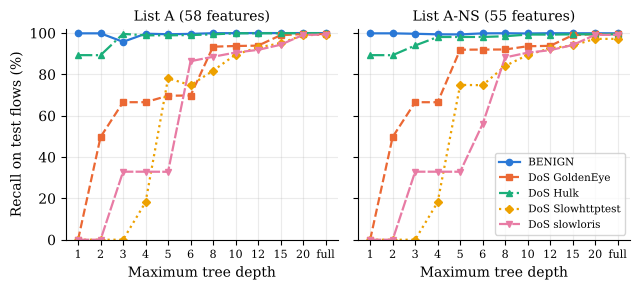

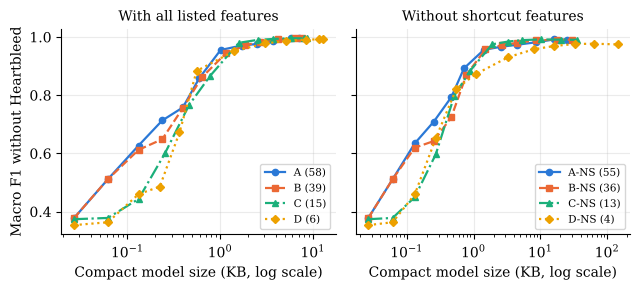

Figures saved to /home/user/threat-detection-model/experiments/figures


In [12]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
MARKERS = ["o", "s", "^", "D", "v"]
STYLES = ["-", "--", "-.", ":", (0, (5, 1))]
plt.rcParams.update({"font.family": "serif", "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
depth_order = [depth_label(d) for d in DEPTHS]
xtick = [("full" if d == "none" else d) for d in depth_order]

# Figure 1: recall of each class as the tree gets shallower (lists A and A-NS)
fig1_sets = [s for s in ["A", "A-NS"] if s in FEATURE_SETS]
fig, axes = plt.subplots(1, len(fig1_sets), figsize=(6.5, 3.0), sharey=True, squeeze=False)
for ax, set_name in zip(axes[0], fig1_sets):
    s = summary[summary["feature_set"] == set_name].set_index("max_depth").loc[depth_order]
    for i, c in enumerate(MAIN_CLASSES):
        ax.plot(range(len(depth_order)), 100 * s[f"recall_{c.replace(' ', '_')}_mean"],
                color=COLORS[i], marker=MARKERS[i], linestyle=STYLES[i], linewidth=1.6,
                markersize=4.5, label=c)
    ax.set_xticks(range(len(depth_order)))
    ax.set_xticklabels(xtick, fontsize=8)
    ax.set_xlabel("Maximum tree depth")
    ax.set_title(f"List {set_name} ({len(FEATURE_SETS[set_name])} features)", fontsize=10)
axes[0][0].set_ylabel("Recall on test flows (%)")
axes[0][0].set_ylim(0, 102)
axes[0][-1].legend(loc="lower right", fontsize=7.5, frameon=True)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_per_class_recall_vs_depth.png", dpi=300)
plt.show()

# Figure 2: macro F1 (without Heartbleed) against compact model size, all lists
fig, axes = plt.subplots(1, 2, figsize=(6.5, 3.0), sharey=True)
for ax, ns in zip(axes, [False, True]):
    for i, base in enumerate(["A", "B", "C", "D"]):
        set_name = f"{base}-NS" if ns else base
        if set_name not in FEATURE_SETS:
            continue
        s = summary[summary["feature_set"] == set_name].set_index("max_depth").loc[depth_order]
        ax.plot(s["compact_bytes_mean"] / 1024, s["macro_f1_no_hb_mean"], color=COLORS[i],
                marker=MARKERS[i], linestyle=STYLES[i], linewidth=1.6, markersize=4.5,
                label=f"{set_name} ({len(FEATURE_SETS[set_name])})")
    ax.set_xscale("log")
    ax.set_xlabel("Compact model size (KB, log scale)")
    ax.set_title("Without shortcut features" if ns else "With all listed features", fontsize=10)
    ax.legend(loc="lower right", fontsize=7.5, frameon=True)
axes[0].set_ylabel("Macro F1 without Heartbleed")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_macro_f1_vs_compact_size.png", dpi=300)
plt.show()
print("Figures saved to", FIG_DIR)